## Group 10 :
* Guettiche  Oussama
* Assabbane  Ali	


In [12]:
import sys
print(sys.executable)

c:\Users\oussa\.venv\Scripts\python.exe


In [13]:
import typing_extensions

print("Location:", typing_extensions.__file__)
print("Sentinel:", hasattr(typing_extensions, "sentinel"))

Location: c:\Users\oussa\.venv\Lib\site-packages\typing_extensions.py
Sentinel: True


In [14]:
import typing_extensions

print("Sentinel:", hasattr(typing_extensions, "sentinel"))

import mlflow
import dagshub

print("MLflow:", mlflow.__version__)
print("DagsHub: OK")

Sentinel: True
MLflow: 3.18.0
DagsHub: OK


In [15]:
import dagshub
import mlflow

dagshub.init(
    repo_owner="oussg98-hash",
    repo_name="Bank-Term-Deposit-Prediction",
    mlflow=True
)

print("Connexion DagsHub configurée !")

Initialized MLflow to track repo "oussg98-hash/Bank-Term-Deposit-Prediction"

Repository oussg98-hash/Bank-Term-Deposit-Prediction initialized!

Connexion DagsHub configurée !


In [16]:
import mlflow

mlflow.set_experiment("Bank-Term-Deposit-Prediction")

with mlflow.start_run(run_name="Test_Connexion"):
    mlflow.log_param("modele", "test")
    mlflow.log_metric("accuracy", 0.85)

print("Expérience enregistrée avec succès !")

2026/11/04 10:05:28 INFO mlflow.tracking.fluent: Experiment with name 'Bank-Term-Deposit-Prediction' does not exist. Creating a new experiment.


🏃 View run Test_Connexion at: https://dagshub.com/oussg98-hash/Bank-Term-Deposit-Prediction.mlflow/#/experiments/0/runs/79754a3c08e346b8a03a3607184d925a
🧪 View experiment at: https://dagshub.com/oussg98-hash/Bank-Term-Deposit-Prediction.mlflow/#/experiments/0
Expérience enregistrée avec succès !


In [ ]:
print("hello")

* Étape 1 : Exploration des données

In [ ]:
import pandas as pd

In [ ]:
# Votre code ici
df = pd.read_csv('Bank_Marketing_Dataset.csv')
df.head()

,ClientID,Age,Gender,MaritalStatus,EducationLevel,EmploymentStatus,JobTitle,Region,SalaryCategory,CustomerSegment,...,LastContactDuration,NumContactsInCampaign,NumPrevCampaignContacts,PrevCampaignOutcome,CallResponseScore,DaysSinceLastContact,PreviousYearDeposit,MarketingScore,ResponsePropensity,TermDepositSubscribed
0,1,46,Male,Divorced,Secondary,Employed,Services,East,Mid,Mass,...,343,4,1,Failure,25.07,475,0,1.7179,0.21,0
1,2,39,Female,Married,Secondary,Self-employed,Blue-collar,Central,Low,Premium,...,198,2,0,Nonexistent,29.11,-1,0,1.6803,0.46,1
2,3,48,Male,Married,Secondary,Self-employed,Services,South,Mid,Mass,...,177,4,4,Failure,15.76,318,0,1.0510,0.22,1
3,4,59,Female,Married,Secondary,Employed,Student,South,Low,Mass,...,132,1,1,Success,40.06,819,0,1.5676,0.30,0
4,5,38,Male,Married,Tertiary,Employed,Retired,North,Low,Mass,...,376,4,1,Failure,26.51,362,0,1.2918,0.33,0


In [ ]:
df.shape

(100000, 45)

In [ ]:
# Afficher toutes les colonnes du dataset

for col in df.columns:
    print(col)

ClientID
Age
Gender
MaritalStatus
EducationLevel
EmploymentStatus
JobTitle
Region
SalaryCategory
CustomerSegment
AnnualIncome
NetWorth
CreditScore
CreditLimit
RiskRating
AccountLengthYears
TenureWithBank
AccountBalance
NumBankProducts
HasCreditCard
HasMortgage
HasPersonalLoan
HasLifeInsurance
HasMutualFunds
InvestmentPortfolioValue
TotalTransactions
AvgTransactionValue
NumOnlineTransactions
NumMobileAppLogins
BranchVisitFrequency
ChannelPreference
WebsiteActivityScore
LastContactChannel
LastContactMonth
LastContactDay
LastContactDuration
NumContactsInCampaign
NumPrevCampaignContacts
PrevCampaignOutcome
CallResponseScore
DaysSinceLastContact
PreviousYearDeposit
MarketingScore
ResponsePropensity
TermDepositSubscribed


In [ ]:
df.describe()

,ClientID,Age,AnnualIncome,NetWorth,CreditScore,CreditLimit,AccountLengthYears,TenureWithBank,AccountBalance,NumBankProducts,...,WebsiteActivityScore,LastContactDuration,NumContactsInCampaign,NumPrevCampaignContacts,CallResponseScore,DaysSinceLastContact,PreviousYearDeposit,MarketingScore,ResponsePropensity,TermDepositSubscribed
count,100000.000000,100000.000000,100000.000000,1.000000e+05,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,...,100000.000000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,50000.500000,40.655890,48468.183203,6.276775e+04,620.413880,26939.264673,6.715130,8.856810,19484.338754,3.198470,...,13.899730,231.762350,2.80729,1.202830,27.697541,349.967990,0.129470,1.580770,0.297264,0.300210
std,28867.657797,11.693051,30612.345921,7.396154e+04,61.732997,10507.544848,4.613791,4.383644,15681.707333,1.259514,...,3.316387,127.480169,0.80822,1.094304,7.991179,332.840906,0.335721,0.255301,0.137629,0.458351
min,1.000000,18.000000,10000.000000,5.000000e+03,363.000000,10738.190000,0.000000,0.000000,523.030000,1.000000,...,0.000000,20.000000,1.00000,0.000000,2.570000,-1.000000,0.000000,0.842400,0.030000,0.000000
25%,25000.750000,32.000000,26193.455000,2.140210e+04,579.000000,19589.182500,3.000000,6.000000,8409.652500,2.000000,...,11.660000,143.000000,2.00000,0.000000,22.190000,-1.000000,0.000000,1.388100,0.190000,0.000000
50%,50000.500000,41.000000,40917.620000,3.959975e+04,620.000000,24205.795000,6.000000,9.000000,14963.830000,3.000000,...,13.860000,203.000000,3.00000,1.000000,26.460000,287.000000,0.000000,1.558900,0.280000,0.000000
75%,75000.250000,49.000000,62838.592500,7.467539e+04,662.000000,31310.512500,10.000000,12.000000,25683.747500,4.000000,...,16.110000,286.000000,3.00000,2.000000,32.000000,643.000000,0.000000,1.759600,0.390000,1.000000
max,100000.000000,85.000000,261230.340000,1.565895e+06,898.000000,110249.820000,27.000000,32.000000,163712.250000,8.000000,...,29.340000,1468.000000,4.00000,8.000000,60.470000,998.000000,1.000000,2.673100,0.600000,1.000000


In [ ]:
df.isna().sum()

ClientID                    0
Age                         0
Gender                      0
MaritalStatus               0
EducationLevel              0
EmploymentStatus            0
JobTitle                    0
Region                      0
SalaryCategory              0
CustomerSegment             0
AnnualIncome                0
NetWorth                    0
CreditScore                 0
CreditLimit                 0
RiskRating                  0
AccountLengthYears          0
TenureWithBank              0
AccountBalance              0
NumBankProducts             0
HasCreditCard               0
HasMortgage                 0
HasPersonalLoan             0
HasLifeInsurance            0
HasMutualFunds              0
InvestmentPortfolioValue    0
TotalTransactions           0
AvgTransactionValue         0
NumOnlineTransactions       0
NumMobileAppLogins          0
BranchVisitFrequency        0
ChannelPreference           0
WebsiteActivityScore        0
LastContactChannel          0
LastContac

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 45 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ClientID                  100000 non-null  int64  
 1   Age                       100000 non-null  int64  
 2   Gender                    100000 non-null  str    
 3   MaritalStatus             100000 non-null  str    
 4   EducationLevel            100000 non-null  str    
 5   EmploymentStatus          100000 non-null  str    
 6   JobTitle                  100000 non-null  str    
 7   Region                    100000 non-null  str    
 8   SalaryCategory            100000 non-null  str    
 9   CustomerSegment           100000 non-null  str    
 10  AnnualIncome              100000 non-null  float64
 11  NetWorth                  100000 non-null  float64
 12  CreditScore               100000 non-null  int64  
 13  CreditLimit               100000 non-null  float64
 14  

In [ ]:
df.select_dtypes(include=["object", "category"]).columns

C:\Users\oussa\AppData\Local\Temp\ipykernel_28308\1747626035.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include=["object", "category"]).columns


Index(['Gender', 'MaritalStatus', 'EducationLevel', 'EmploymentStatus',
       'JobTitle', 'Region', 'SalaryCategory', 'CustomerSegment', 'RiskRating',
       'HasCreditCard', 'HasMortgage', 'HasPersonalLoan', 'HasLifeInsurance',
       'HasMutualFunds', 'ChannelPreference', 'LastContactChannel',
       'LastContactMonth', 'LastContactDay', 'PrevCampaignOutcome'],
      dtype='str')

In [ ]:
df["TermDepositSubscribed"].value_counts()

TermDepositSubscribed
0    69979
1    30021
Name: count, dtype: int64

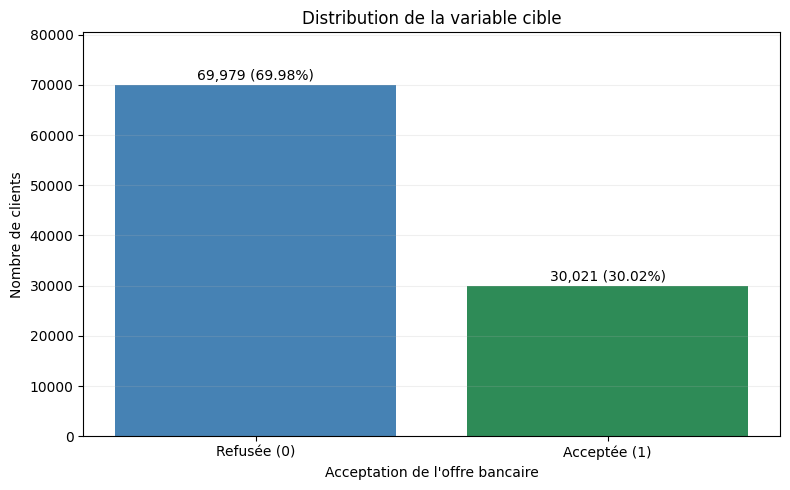

In [ ]:
import matplotlib.pyplot as plt

# Distribution de la variable cible
counts = df["TermDepositSubscribed"].value_counts().sort_index()

# Création du diagramme
plt.figure(figsize=(8, 5))

bars = plt.bar(
    ["Refusée (0)", "Acceptée (1)"],
    counts.values,
    color=["steelblue", "seagreen"]
)

# Afficher les nombres et pourcentages
total = counts.sum()

for bar in bars:
    valeur = int(bar.get_height())
    pourcentage = valeur / total * 100

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        valeur + 1000,
        f"{valeur:,} ({pourcentage:.2f}%)",
        ha="center"
    )

plt.title("Distribution de la variable cible")
plt.xlabel("Acceptation de l'offre bancaire")
plt.ylabel("Nombre de clients")
plt.ylim(0, counts.max() * 1.15)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

### Interprétation de la distribution de la variable cible

Le jeu de données contient 100 000 clients.

- **69 979 clients (69,98 %)** n'ont pas souscrit à l'offre bancaire.
- **30 021 clients (30,02 %)** ont accepté l'offre bancaire.

On observe un déséquilibre modéré entre les deux classes.

Pour évaluer les modèles de classification, nous utiliserons plusieurs métriques, notamment la précision, le rappel, le F1-score et l'accuracy.

Le F1-score sera particulièrement utile pour comparer les performances des modèles sur la classe positive.


# Étape 2 : Prétraitement des données



* Cette étape consiste à préparer les données pour l'entraînement des modèles de classification.

* Nous allons sélectionner les variables pertinentes,encoder les variables catégorielles et préparer les données pour la modélisation.




In [ ]:

# nous supprimons la colonne ClientID, car elle représente
# uniquement un identifiant et n'apporte pas d'information
# pertinente pour la prédiction.

df = df.drop(columns=["ClientID"])

# Vérifier les dimensions après la suppression
df.shape

(100000, 44)

In [ ]:
df.head()

,Age,Gender,MaritalStatus,EducationLevel,EmploymentStatus,JobTitle,Region,SalaryCategory,CustomerSegment,AnnualIncome,...,LastContactDuration,NumContactsInCampaign,NumPrevCampaignContacts,PrevCampaignOutcome,CallResponseScore,DaysSinceLastContact,PreviousYearDeposit,MarketingScore,ResponsePropensity,TermDepositSubscribed
0,46,Male,Divorced,Secondary,Employed,Services,East,Mid,Mass,50548.83,...,343,4,1,Failure,25.07,475,0,1.7179,0.21,0
1,39,Female,Married,Secondary,Self-employed,Blue-collar,Central,Low,Premium,28168.89,...,198,2,0,Nonexistent,29.11,-1,0,1.6803,0.46,1
2,48,Male,Married,Secondary,Self-employed,Services,South,Mid,Mass,35797.77,...,177,4,4,Failure,15.76,318,0,1.0510,0.22,1
3,59,Female,Married,Secondary,Employed,Student,South,Low,Mass,10000.00,...,132,1,1,Success,40.06,819,0,1.5676,0.30,0
4,38,Male,Married,Tertiary,Employed,Retired,North,Low,Mass,24344.60,...,376,4,1,Failure,26.51,362,0,1.2918,0.33,0



## 2.1 Sélection des variables




In [ ]:
#Avant la séparation des données, nous vérifions les variables explicatives afin d'identifier celles qui sont pertinentes pour la prédiction
#  et d'éviter les risques de fuite de données (Data Leakage).

In [ ]:
# Examiner les variables potentiellement problématiques
colonnes_a_verifier = [
    "ResponsePropensity",
    "LastContactDuration",
    "MarketingScore"
]

df[colonnes_a_verifier].describe()

,ResponsePropensity,LastContactDuration,MarketingScore
count,100000.000000,100000.000000,100000.000000
mean,0.297264,231.762350,1.580770
std,0.137629,127.480169,0.255301
min,0.030000,20.000000,0.842400
25%,0.190000,143.000000,1.388100
50%,0.280000,203.000000,1.558900
75%,0.390000,286.000000,1.759600
max,0.600000,1468.000000,2.673100



## 2.2 Exclusion des variables potentiellement problématiques

Afin de limiter les risques de fuite de données, nous excluons provisoirement les variables ResponsePropensity, LastContactDuration et MarketingScore.

Ces variables pourront être réévaluées après vérification de leur définition et de leur disponibilité au moment de la prédiction.


In [ ]:
# Exclure provisoirement les variables à risque
colonnes_a_exclure = [
    "ResponsePropensity",
    "LastContactDuration",
    "MarketingScore"
]

df = df.drop(columns=colonnes_a_exclure)

# Vérifier les dimensions
print("Dimensions :", df.shape)

Dimensions : (100000, 41)



# Étape 3 : Séparation des données

Nous divisons notre jeu de données en trois ensembles :

- **70 % pour l'entraînement** : apprendre les relations entre les caractéristiques des clients et l'acceptation de l'offre.
- **15 % pour la validation** : comparer les modèles et ajuster leurs paramètres.
- **15 % pour le test** : évaluer les performances finales sur des données jamais utilisées pendant l'entraînement ou la sélection des modèles.

Nous utilisons une séparation stratifiée pour conserver approximativement la proportion des deux classes.


In [ ]:
# Séparer les variables explicatives et la cible
X = df.drop(columns=["TermDepositSubscribed"])
y = df["TermDepositSubscribed"]

print("X :", X.shape)
print("y :", y.shape)

X : (100000, 40)
y : (100000,)


In [ ]:
from sklearn.model_selection import train_test_split

# 70 % entraînement et 30 % temporaire
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# 15 % validation et 15 % test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Vérifier les dimensions
print("Train :", X_train.shape)
print("Validation :", X_val.shape)
print("Test :", X_test.shape)

Train : (70000, 40)
Validation : (15000, 40)
Test : (15000, 40)


In [ ]:
# Vérifier que la proportion des deux classes (0 et 1)
# est conservée dans les ensembles Train, Validation et Test
# grâce à la séparation stratifiée.

print("Train :")
print(y_train.value_counts(normalize=True))

print("\nValidation :")
print(y_val.value_counts(normalize=True))

print("\nTest :")
print(y_test.value_counts(normalize=True))

Train :
TermDepositSubscribed
0    0.699786
1    0.300214
Name: proportion, dtype: float64

Validation :
TermDepositSubscribed
0    0.6998
1    0.3002
Name: proportion, dtype: float64

Test :
TermDepositSubscribed
0    0.6998
1    0.3002
Name: proportion, dtype: float64



### Conclusion de la séparation

Les données ont été divisées en trois ensembles : 70 % pour l'entraînement, 15 % pour la validation et 15 % pour le test.

La séparation stratifiée a permis de conserver approximativement la même proportion des deux classes dans chaque ensemble.



# Étape 4 : Encodage et standardisation

* Cette étape consiste à transformer les variables catégorielles en données numériques et
* à standardiser les variables numériques afin de préparer les données pour l'entraînement des modèles.


## 4.1 Identifier les variables numériques et catégorielles

In [ ]:

colonnes_numeriques = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

colonnes_categorielles = X_train.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

print("Variables numériques :", len(colonnes_numeriques))
print("Variables catégorielles :", len(colonnes_categorielles))

Variables numériques : 21
Variables catégorielles : 19



## 4.2 Création du préprocesseur

Nous utilisons ColumnTransformer pour appliquer deux transformations :

- StandardScaler pour standardiser les variables numériques.
- OneHotEncoder pour convertir les variables catégorielles en variables numériques.

Les transformations seront apprises uniquement à partir des données d'entraînement afin d'éviter la fuite de données.


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Créer le préprocesseur
preprocesseur = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), colonnes_numeriques),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         colonnes_categorielles)
    ]
)

# Afficher le préprocesseur
print(preprocesseur)

ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['Age', 'AnnualIncome', 'NetWorth',
                                  'CreditScore', 'CreditLimit',
                                  'AccountLengthYears', 'TenureWithBank',
                                  'AccountBalance', 'NumBankProducts',
                                  'InvestmentPortfolioValue',
                                  'TotalTransactions', 'AvgTransactionValue',
                                  'NumOnlineTransactions', 'NumMobileAppLogins',
                                  'BranchVisitFrequency',
                                  'WebsiteActivityScore',...
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['Gender', 'MaritalStatus', 'EducationLevel',
                                  'EmploymentStatus', 'JobTitle', 'Region',
                                  'SalaryCategory', 'CustomerSegment',
                  


## 4.3 Vérification du préprocesseur

Nous vérifions que le préprocesseur contient les transformations nécessaires pour les variables numériques et catégorielles.

Le préprocesseur sera ensuite intégré dans un Pipeline pour garantir que les transformations sont apprises uniquement à partir des données d'entraînement.


In [ ]:
# Vérifier les transformations du préprocesseur

for nom, transformation, colonnes in preprocesseur.transformers:
    print("Transformation :", nom)
    print("Méthode :", transformation)
    print("Nombre de colonnes :", len(colonnes))
    print("------------------------------")

Transformation : num
Méthode : StandardScaler()
Nombre de colonnes : 21
------------------------------
Transformation : cat
Méthode : OneHotEncoder(handle_unknown='ignore')
Nombre de colonnes : 19
------------------------------



# Étape 5 : Entraînement des modèles

Nous allons entraîner et comparer trois modèles de classification binaire : la régression logistique, le Random Forest et un réseau de neurones MLP avec TensorFlow/Keras.

Les modèles seront évalués sur le même ensemble de validation afin de comparer leurs performances.

## 5.1 Entraînement de la Régression logistique

Nous commençons par la régression logistique, qui servira de modèle de référence (baseline).

Nous utilisons un Pipeline pour appliquer automatiquement le prétraitement des données avant l'entraînement du modèle.


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Créer le pipeline avec le prétraitement et le modèle
modele_logistique = Pipeline([
    ("pretraitement", preprocesseur),
    ("classification", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Entraîner le modèle sur les données Train
modele_logistique.fit(X_train, y_train)

print("Entraînement de la régression logistique terminé.")

Entraînement de la régression logistique terminé.



## 5.2 Évaluation de la Régression logistique

Après l'entraînement, nous évaluons le modèle sur l'ensemble de validation (15 % des données).

Nous utilisons quatre métriques :
- Accuracy : proportion totale de prédictions correctes.
- Precision : proportion de vrais positifs parmi les prédictions positives.
- Recall : proportion de vrais positifs détectés.
- F1-score : moyenne harmonique entre la précision et le rappel.

Le F1-score sera une métrique importante pour comparer les modèles.


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Prédire les réponses des clients de validation
y_pred_logistique = modele_logistique.predict(X_val)

# Calculer les métriques
accuracy_logistique = accuracy_score(y_val, y_pred_logistique)
precision_logistique = precision_score(y_val, y_pred_logistique)
recall_logistique = recall_score(y_val, y_pred_logistique)
f1_logistique = f1_score(y_val, y_pred_logistique)

# Afficher les résultats
print("Résultats de la Régression logistique :")
print(f"Accuracy  : {accuracy_logistique:.4f}")
print(f"Precision : {precision_logistique:.4f}")
print(f"Recall    : {recall_logistique:.4f}")
print(f"F1-score  : {f1_logistique:.4f}")

Résultats de la Régression logistique :
Accuracy  : 0.7091
Precision : 0.5457
Recall    : 0.1843
F1-score  : 0.2756



### 5.2.1 Matrice de confusion

La matrice de confusion permet de visualiser les prédictions correctes et incorrectes du modèle.

Elle présente les vrais négatifs (TN), les faux positifs (FP), les faux négatifs (FN) et les vrais positifs (TP).

Cette analyse est particulièrement importante pour identifier les clients intéressés par l'offre bancaire que le modèle n'a pas détectés.


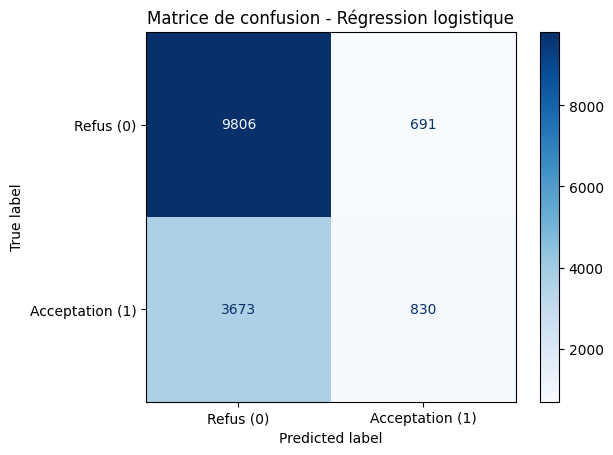

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculer la matrice de confusion
matrice_logistique = confusion_matrix(y_val, y_pred_logistique)

# Afficher la matrice
affichage = ConfusionMatrixDisplay(
    confusion_matrix=matrice_logistique,
    display_labels=["Refus (0)", "Acceptation (1)"]
)

affichage.plot(cmap="Blues", values_format="d")
plt.title("Matrice de confusion - Régression logistique")
plt.show()


### Interprétation des résultats

La régression logistique obtient une accuracy de 70,91 %, mais un recall de seulement 18,43 % et un F1-score de 27,56 %.

La matrice de confusion montre que le modèle détecte correctement 830 clients ayant accepté l'offre, mais ne détecte pas 3 673 autres clients qui l'ont réellement acceptée.

Le modèle privilégie donc les prédictions de refus et manque une grande partie des clients intéressés.

Nous allons comparer ces résultats avec ceux du Random Forest et du réseau de neurones MLP afin de rechercher un modèle plus performant.



## 5.3 Entraînement du Random Forest

Le Random Forest est un algorithme de classification qui combine plusieurs arbres de décision.

Nous allons entraîner ce modèle avec les mêmes données d'entraînement et le même prétraitement que la régression logistique afin de comparer leurs performances.


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone

# Créer le pipeline Random Forest
modele_forest = Pipeline([
    ("pretraitement", clone(preprocesseur)),
    ("classification", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Entraîner le modèle sur les données Train
modele_forest.fit(X_train, y_train)

print("Entraînement du Random Forest terminé.")

Entraînement du Random Forest terminé.



### 5.3.1 Évaluation du Random Forest

Après l'entraînement, nous évaluons le Random Forest sur l'ensemble de validation.

Nous calculons les mêmes métriques que pour la régression logistique : Accuracy, Precision, Recall et F1-score.

Cette évaluation permettra de comparer les performances des deux modèles sur les mêmes données.


In [ ]:
# Prédire les réponses des clients de validation
y_pred_forest = modele_forest.predict(X_val)

# Calculer les métriques
accuracy_forest = accuracy_score(y_val, y_pred_forest)
precision_forest = precision_score(y_val, y_pred_forest)
recall_forest = recall_score(y_val, y_pred_forest)
f1_forest = f1_score(y_val, y_pred_forest)

# Afficher les résultats
print("Résultats du Random Forest :")
print(f"Accuracy  : {accuracy_forest:.4f}")
print(f"Precision : {precision_forest:.4f}")
print(f"Recall    : {recall_forest:.4f}")
print(f"F1-score  : {f1_forest:.4f}")

Résultats du Random Forest :
Accuracy  : 0.7079
Precision : 0.5456
Recall    : 0.1608
F1-score  : 0.2484



### 5.3.3 Comparaison des modèles de classification

Nous comparons les performances de la régression logistique et du Random Forest sur l'ensemble de validation.

Les métriques utilisées sont l'Accuracy, la Precision, le Recall et le F1-score.

L'objectif est d'identifier le modèle le plus performant, en accordant une importance particulière au F1-score.


In [ ]:
import pandas as pd

# Créer un tableau comparatif des modèles
comparaison = pd.DataFrame({
    "Modèle": ["Régression logistique", "Random Forest"],
    "Accuracy": [accuracy_logistique, accuracy_forest],
    "Precision": [precision_logistique, precision_forest],
    "Recall": [recall_logistique, recall_forest],
    "F1-score": [f1_logistique, f1_forest]
})

# Afficher les résultats en pourcentage
display(comparaison.style.format({
    "Accuracy": "{:.2%}",
    "Precision": "{:.2%}",
    "Recall": "{:.2%}",
    "F1-score": "{:.2%}"
}))

,Modèle,Accuracy,Precision,Recall,F1-score
0,Régression logistique,70.91%,54.57%,18.43%,27.56%
1,Random Forest,70.79%,54.56%,16.08%,24.84%


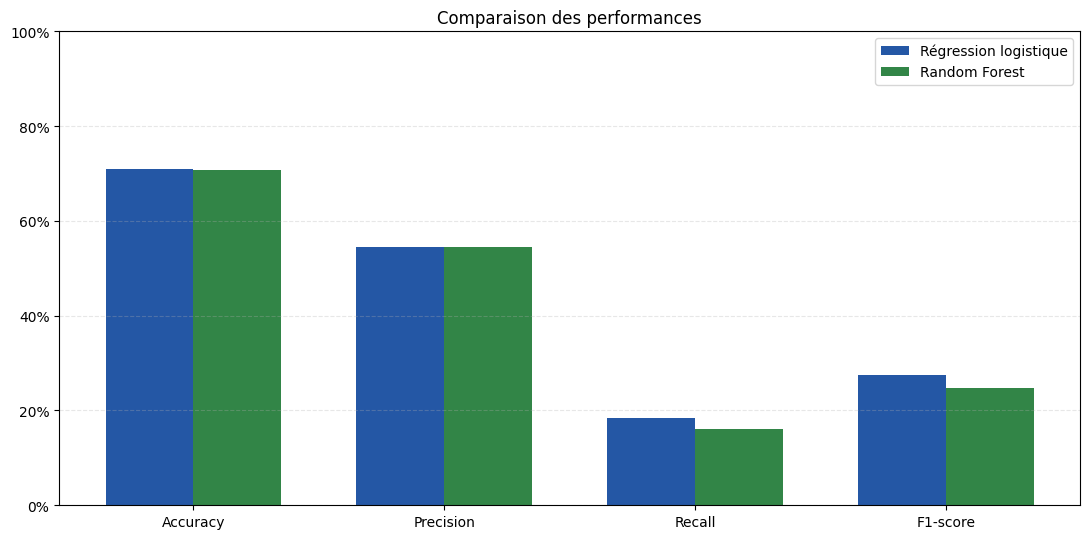

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import PercentFormatter

# Préparer les données du graphique
metriques = ["Accuracy", "Precision", "Recall", "F1-score"]

logistique = [
    accuracy_logistique,
    precision_logistique,
    recall_logistique,
    f1_logistique
]

forest = [
    accuracy_forest,
    precision_forest,
    recall_forest,
    f1_forest
]

# Définir les positions des barres
x = np.arange(len(metriques))
largeur = 0.35

# Créer le graphique
fig, ax = plt.subplots(figsize=(11, 5.5))

ax.bar(x - largeur/2, logistique, largeur,
       label="Régression logistique", color="#2457A5")

ax.bar(x + largeur/2, forest, largeur,
       label="Random Forest", color="#328547")

# Personnaliser le graphique
ax.set_title("Comparaison des performances")
ax.set_xticks(x)
ax.set_xticklabels(metriques)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()


### Conclusion de la comparaison

La régression logistique présente de meilleures performances que le Random Forest sur l'ensemble de validation.

Son F1-score est de 27,56 %, contre 24,84 % pour le Random Forest. Son recall est également supérieur (18,43 % contre 16,08 %).

Cependant, les deux modèles détectent une faible proportion des clients ayant réellement accepté l'offre bancaire.

La prochaine étape consiste à entraîner un réseau de neurones MLP avec TensorFlow/Keras, puis à comparer ses performances avec celles des deux premiers modèles.



## 5.4 Entraînement du réseau de neurones MLP

Nous allons développer un réseau de neurones artificiels de type Multi-Layer Perceptron (MLP) avec TensorFlow/Keras.

Ce modèle sera utilisé pour prédire si un client acceptera ou non une offre bancaire.




### 5.4.1 instalation de TensorFlow

In [ ]:
import tensorflow as tf


### 5.4.2 Préparation des données

Application du StandardScaler et du OneHotEncoder sur les données pour entraîner le MLP.


In [ ]:
from sklearn.base import clone

# Créer une copie du préprocesseur
preprocesseur_mlp = clone(preprocesseur)

# Appliquer le prétraitement
X_train_mlp = preprocesseur_mlp.fit_transform(X_train)
X_val_mlp = preprocesseur_mlp.transform(X_val)

# Convertir les données en tableaux NumPy
if hasattr(X_train_mlp, "toarray"):
    X_train_mlp = X_train_mlp.toarray()

if hasattr(X_val_mlp, "toarray"):
    X_val_mlp = X_val_mlp.toarray()

# Afficher les dimensions
print("Train :", X_train_mlp.shape)
print("Validation :", X_val_mlp.shape)

Train : (70000, 98)
Validation : (15000, 98)



### 5.4.3 Création du modèle MLP

Le réseau contient deux couches cachées de 64 et 32 neurones avec ReLU, et une couche de sortie avec Sigmoid pour la classification binaire.


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

# Créer le réseau de neurones
modele_mlp = Sequential([
    Input(shape=(X_train_mlp.shape[1],)),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(1, activation="sigmoid")
])

# Afficher l'architecture du modèle
modele_mlp.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │         6,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,449 (33.00 KB)

 Trainable params: 8,449 (33.00 KB)

 Non-trainable params: 0 (0.00 B)


### 5.4.4 Compilation du modèle MLP

Utilisation de l'optimiseur Adam, de la fonction de perte Binary Crossentropy et de l'Accuracy pour suivre l'entraînement.


In [ ]:
from tensorflow.keras.optimizers import Adam

# Compiler le modèle
modele_mlp.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Compilation du MLP terminée.")

Compilation du MLP terminée.



### 5.4.5 Entraînement du MLP

Entraînement du modèle sur 20 epochs avec un batch size de 256. Les données de validation permettent de suivre les performances du modèle.


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

# Arrêter l'entraînement si la validation ne s'améliore plus
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Entraîner le réseau de neurones
historique_mlp = modele_mlp.fit(
    X_train_mlp,
    y_train,
    validation_data=(X_val_mlp, y_val),
    epochs=20,
    batch_size=256,
    callbacks=[early_stopping],
    verbose=1
)

print("Entraînement du MLP terminé.")

Epoch 1/20
274/274 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.6994 - loss: 0.5842 - val_accuracy: 0.7056 - val_loss: 0.5721
Epoch 2/20
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7121 - loss: 0.5675 - val_accuracy: 0.7076 - val_loss: 0.5711
Epoch 3/20
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7141 - loss: 0.5655 - val_accuracy: 0.7059 - val_loss: 0.5710
Epoch 4/20
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7158 - loss: 0.5632 - val_accuracy: 0.7065 - val_loss: 0.5727
Epoch 5/20
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7170 - loss: 0.5615 - val_accuracy: 0.7081 - val_loss: 0.5715
Epoch 6/20
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7177 - loss: 0.5596 - val_accuracy: 0.7083 - val_loss: 0.5723
Entraînement du MLP terminé.



### 5.4.6 Visualisation de Loss et Val_loss

Évolution des pertes d'entraînement et de validation avec EarlyStopping.


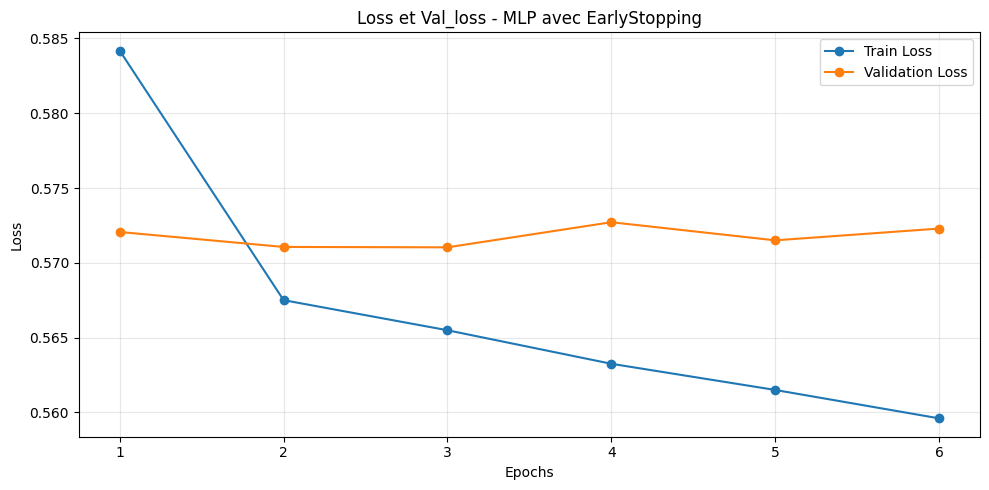

In [ ]:
import matplotlib.pyplot as plt

# Récupérer les pertes
loss = historique_mlp.history["loss"]
val_loss = historique_mlp.history["val_loss"]

epochs = range(1, len(loss) + 1)

# Tracer les courbes
plt.figure(figsize=(10, 5))

plt.plot(epochs, loss, marker="o", label="Train Loss")
plt.plot(epochs, val_loss, marker="o", label="Validation Loss")

plt.title("Loss et Val_loss - MLP avec EarlyStopping")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### Interprétation du graphique

La Train Loss diminue progressivement, tandis que la Validation Loss reste presque stable après la troisième epoch.

Le modèle commence à montrer des signes de surapprentissage. EarlyStopping arrête l'entraînement à la sixième epoch et restaure les meilleurs poids.



### 5.4.7 Évaluation du MLP

Calcul de l'Accuracy, de la Precision, du Recall et du F1-score sur les données de validation.


In [ ]:
# Prédire les probabilités d'acceptation
y_proba_mlp = modele_mlp.predict(X_val_mlp).ravel()

# Convertir les probabilités en classes (0 ou 1)
y_pred_mlp = (y_proba_mlp >= 0.5).astype(int)

# Calculer les métriques
accuracy_mlp = accuracy_score(y_val, y_pred_mlp)
precision_mlp = precision_score(y_val, y_pred_mlp)
recall_mlp = recall_score(y_val, y_pred_mlp)
f1_mlp = f1_score(y_val, y_pred_mlp)

# Afficher les résultats
print("Résultats du MLP :")
print(f"Accuracy  : {accuracy_mlp:.4f}")
print(f"Precision : {precision_mlp:.4f}")
print(f"Recall    : {recall_mlp:.4f}")
print(f"F1-score  : {f1_mlp:.4f}")

469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Résultats du MLP :
Accuracy  : 0.7059
Precision : 0.5290
Recall    : 0.1865
F1-score  : 0.2758



## 5.5 Comparaison des trois modèles

Comparaison de la régression logistique, du Random Forest et du MLP à partir des résultats obtenus sur les données de validation.


In [ ]:
# Créer le tableau comparatif des trois modèles
comparaison_finale = pd.DataFrame({
    "Modèle": ["Régression logistique", "Random Forest", "MLP"],
    "Accuracy": [accuracy_logistique, accuracy_forest, accuracy_mlp],
    "Precision": [precision_logistique, precision_forest, precision_mlp],
    "Recall": [recall_logistique, recall_forest, recall_mlp],
    "F1-score": [f1_logistique, f1_forest, f1_mlp]
})

# Afficher les résultats en pourcentage
display(comparaison_finale.style.format({
    "Accuracy": "{:.2%}",
    "Precision": "{:.2%}",
    "Recall": "{:.2%}",
    "F1-score": "{:.2%}"
}))

,Modèle,Accuracy,Precision,Recall,F1-score
0,Régression logistique,70.91%,54.57%,18.43%,27.56%
1,Random Forest,70.79%,54.56%,16.08%,24.84%
2,MLP,70.59%,52.90%,18.65%,27.58%


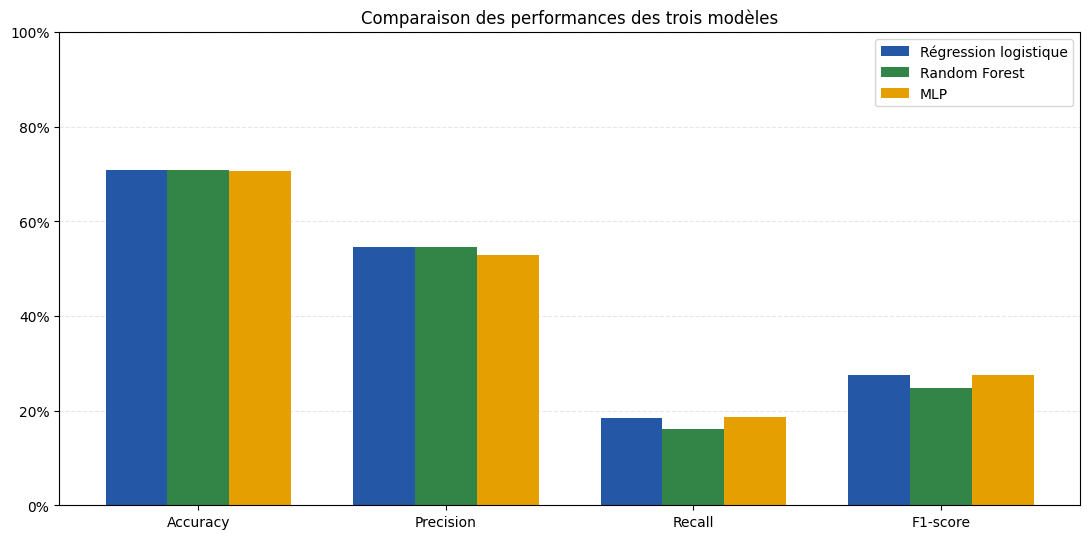

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Préparer les métriques
metriques = ["Accuracy", "Precision", "Recall", "F1-score"]
x = np.arange(len(metriques))
largeur = 0.25

# Récupérer les résultats des modèles
logistique = comparaison_finale.iloc[0, 1:].to_numpy(dtype=float)
forest = comparaison_finale.iloc[1, 1:].to_numpy(dtype=float)
mlp = comparaison_finale.iloc[2, 1:].to_numpy(dtype=float)

# Créer le graphique
fig, ax = plt.subplots(figsize=(11, 5.5))

ax.bar(x - largeur, logistique, largeur,
       label="Régression logistique", color="#2457A5")

ax.bar(x, forest, largeur,
       label="Random Forest", color="#328547")

ax.bar(x + largeur, mlp, largeur,
       label="MLP", color="#E69F00")

# Personnaliser le graphique
ax.set_title("Comparaison des performances des trois modèles")
ax.set_xticks(x)
ax.set_xticklabels(metriques)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
ax.legend()

plt.tight_layout()
plt.show()


### Conclusion de la comparaison

Le MLP obtient le meilleur F1-score (27,58 %) et le meilleur recall (18,65 %), avec une légère avance sur la régression logistique.

La régression logistique obtient la meilleure accuracy (70,91 %) et la meilleure précision (54,57 %).

Les performances restent limitées, surtout pour le recall. Une optimisation des modèles et du seuil de classification sera nécessaire.



## 6. Optimisation des modèles

### 6.1 Optimisation du seuil de classification

Recherche du meilleur seuil de classification pour améliorer le F1-score sur les données de validation.


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score

# Calculer les probabilités d'acceptation
proba_logistique = modele_logistique.predict_proba(X_val)[:, 1]

# Tester plusieurs seuils
seuils = np.arange(0.10, 0.91, 0.05)
resultats_seuils = []

for seuil in seuils:
    predictions = (proba_logistique >= seuil).astype(int)
    score = f1_score(y_val, predictions)

    resultats_seuils.append({
        "Seuil": round(seuil, 2),
        "F1-score": score
    })

# Afficher les résultats
df_seuils = pd.DataFrame(resultats_seuils)

display(df_seuils)

# Trouver le meilleur seuil
meilleure_ligne = df_seuils.loc[df_seuils["F1-score"].idxmax()]

print("Meilleur seuil :", round(meilleure_ligne["Seuil"], 2))
print("Meilleur F1-score :", round(meilleure_ligne["F1-score"], 4))

,Seuil,F1-score
0,0.10,0.463873
1,0.15,0.480825
2,0.20,0.503700
3,0.25,0.511437
4,0.30,0.500933
5,0.35,0.470511
6,0.40,0.413277
7,0.45,0.349853
8,0.50,0.275564
9,0.55,0.202809


Meilleur seuil : 0.25
Meilleur F1-score : 0.5114



### 6.2 Visualisation du F1-score selon le seuil

Comparaison des valeurs du F1-score pour différents seuils de classification.


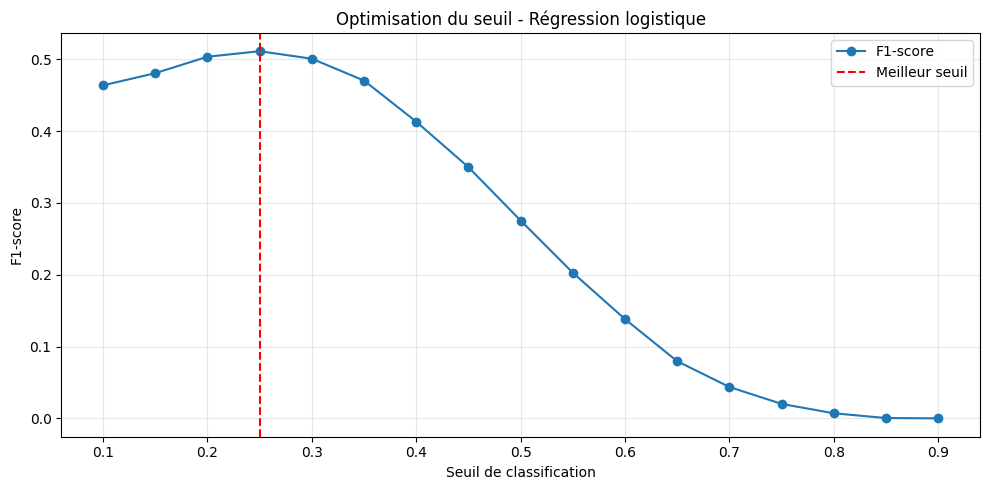

In [ ]:
import matplotlib.pyplot as plt

# Tracer les résultats des seuils
plt.figure(figsize=(10, 5))

plt.plot(
    df_seuils["Seuil"],
    df_seuils["F1-score"],
    marker="o",
    label="F1-score"
)

# Afficher le meilleur seuil
plt.axvline(
    x=meilleure_ligne["Seuil"],
    color="red",
    linestyle="--",
    label="Meilleur seuil"
)

plt.title("Optimisation du seuil - Régression logistique")
plt.xlabel("Seuil de classification")
plt.ylabel("F1-score")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### Résultat de l'optimisation

Le meilleur seuil testé pour la régression logistique est de 0,25, avec un F1-score de 51,14 %, contre 27,56 % avec le seuil initial de 0,50.

L'ajustement du seuil améliore donc le F1-score sur les données de validation.



### 6.3 Optimisation du seuil de Random Forest et du MLP

Recherche du meilleur seuil de classification pour les deux modèles afin d'améliorer leur F1-score.


In [ ]:
# Calculer les probabilités des deux modèles
proba_forest = modele_forest.predict_proba(X_val)[:, 1]
proba_mlp = y_proba_mlp

# Tester les mêmes seuils
seuils = np.arange(0.10, 0.91, 0.05)

resultats_optimisation = []

for nom, probabilites in [
    ("Random Forest", proba_forest),
    ("MLP", proba_mlp)
]:
    for seuil in seuils:
        predictions = (probabilites >= seuil).astype(int)

        resultats_optimisation.append({
            "Modèle": nom,
            "Seuil": round(seuil, 2),
            "F1-score": f1_score(y_val, predictions)
        })

# Créer le tableau
df_optimisation = pd.DataFrame(resultats_optimisation)

# Trouver le meilleur seuil pour chaque modèle
meilleurs_seuils = df_optimisation.loc[
    df_optimisation.groupby("Modèle")["F1-score"].idxmax()
].reset_index(drop=True)

display(meilleurs_seuils)

,Modèle,Seuil,F1-score
0,MLP,0.25,0.509307
1,Random Forest,0.30,0.499576



### 6.4 Comparaison avant et après optimisation

Comparaison des F1-scores des trois modèles avant et après l'optimisation du seuil de classification.


In [ ]:
# Récupérer les meilleurs F1-scores
f1_logistique_opt = meilleure_ligne["F1-score"]

f1_forest_opt = meilleurs_seuils.loc[
    meilleurs_seuils["Modèle"] == "Random Forest", "F1-score"
].iloc[0]

f1_mlp_opt = meilleurs_seuils.loc[
    meilleurs_seuils["Modèle"] == "MLP", "F1-score"
].iloc[0]

# Créer le tableau comparatif
comparaison_optimisation = pd.DataFrame({
    "Modèle": ["Régression logistique", "Random Forest", "MLP"],
    "F1 avant": [f1_logistique, f1_forest, f1_mlp],
    "F1 après": [f1_logistique_opt, f1_forest_opt, f1_mlp_opt]
})

display(comparaison_optimisation.style.format({
    "F1 avant": "{:.2%}",
    "F1 après": "{:.2%}"
}))

,Modèle,F1 avant,F1 après
0,Régression logistique,27.56%,51.14%
1,Random Forest,24.84%,49.96%
2,MLP,27.58%,50.93%


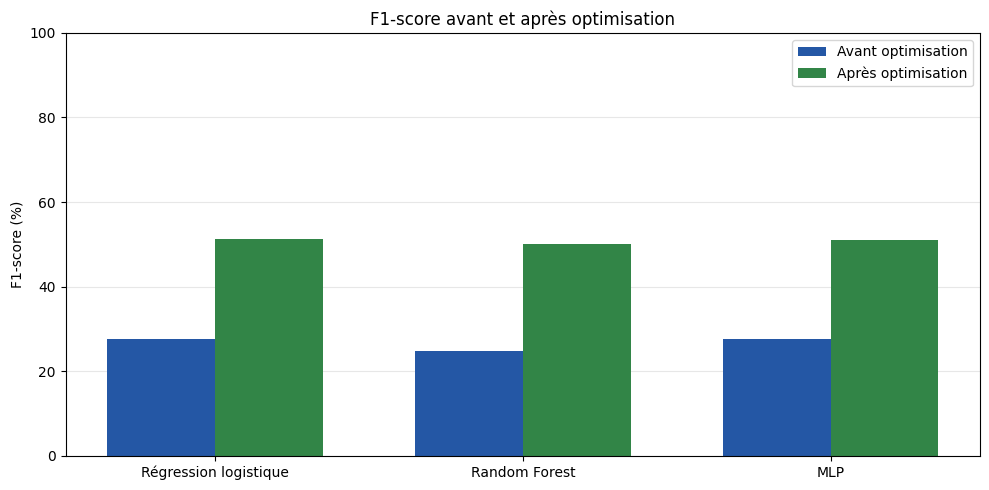

In [ ]:
# Préparer les données
x = np.arange(len(comparaison_optimisation))
largeur = 0.35

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    x - largeur / 2,
    comparaison_optimisation["F1 avant"] * 100,
    largeur,
    label="Avant optimisation",
    color="#2457A5"
)

ax.bar(
    x + largeur / 2,
    comparaison_optimisation["F1 après"] * 100,
    largeur,
    label="Après optimisation",
    color="#328547"
)

ax.set_title("F1-score avant et après optimisation")
ax.set_ylabel("F1-score (%)")
ax.set_xticks(x)
ax.set_xticklabels(comparaison_optimisation["Modèle"])
ax.set_ylim(0, 100)

ax.legend()
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


### Conclusion de l'optimisation

L'ajustement du seuil de classification améliore le F1-score des trois modèles.

La régression logistique obtient le meilleur résultat sur les données de validation, avec un F1-score de 51,14 % pour un seuil de 0,25.

Nous retenons donc provisoirement ce modèle pour l'évaluation finale sur les données de test.



## 7. Évaluation finale du modèle

### 7.1 Prédiction sur les données de Test

Évaluation de la régression logistique sur les données de Test avec le seuil optimisé de 0,25.


In [ ]:
# Calculer les probabilités sur les données de Test
proba_test = modele_logistique.predict_proba(X_test)[:, 1]

# Appliquer le seuil optimisé
seuil_optimal = 0.25

y_pred_test = (proba_test >= seuil_optimal).astype(int)

print("Nombre de clients testés :", len(y_pred_test))

Nombre de clients testés : 15000



### 7.2 Calcul des métriques finales

Calcul de l'Accuracy, de la Precision, du Recall et du F1-score sur les données de Test.


In [ ]:
# Calculer les métriques finales
accuracy_test = accuracy_score(y_test, y_pred_test)
precision_test = precision_score(y_test, y_pred_test)
recall_test = recall_score(y_test, y_pred_test)
f1_test = f1_score(y_test, y_pred_test)

# Afficher les résultats
print("Résultats finaux - Régression logistique :")
print(f"Accuracy  : {accuracy_test:.4f}")
print(f"Precision : {precision_test:.4f}")
print(f"Recall    : {recall_test:.4f}")
print(f"F1-score  : {f1_test:.4f}")

Résultats finaux - Régression logistique :
Accuracy  : 0.5785
Precision : 0.3910
Recall    : 0.7249
F1-score  : 0.5080



### 7.3 Matrice de confusion finale

Visualisation des prédictions correctes et incorrectes du modèle sur les données de Test.


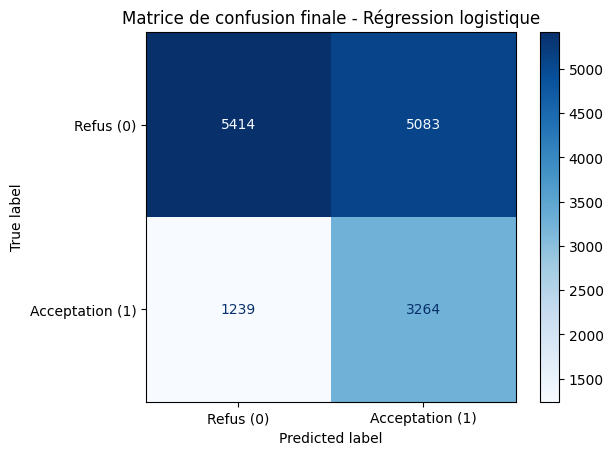

In [ ]:
# Calculer la matrice de confusion
matrice_test = confusion_matrix(y_test, y_pred_test)

# Afficher la matrice
affichage_test = ConfusionMatrixDisplay(
    confusion_matrix=matrice_test,
    display_labels=["Refus (0)", "Acceptation (1)"]
)

affichage_test.plot(cmap="Blues", values_format="d")

plt.title("Matrice de confusion finale - Régression logistique")
plt.show()

###  Interprétation des résultats finaux

Le modèle de régression logistique a été évalué sur 15 000 clients avec un seuil de classification de 0,25.

**Matrice de confusion :**

- **Vrais négatifs (TN = 5 414) :** clients ayant refusé l'offre et correctement identifiés par le modèle.
- **Faux positifs (FP = 5 083) :** clients ayant refusé l'offre, mais pour lesquels le modèle prédit une acceptation.
- **Faux négatifs (FN = 1 239) :** clients ayant accepté l'offre, mais pour lesquels le modèle prédit un refus.
- **Vrais positifs (TP = 3 264) :** clients ayant accepté l'offre et correctement identifiés par le modèle.

**Interprétation des métriques :**

- **Accuracy (57,85 %) :** le modèle réalise des prédictions correctes pour environ 58 % des clients.
- **Precision (39,10 %) :** parmi les clients pour lesquels le modèle prédit une acceptation, environ 39 % acceptent réellement l'offre.
- **Recall (72,49 %) :** le modèle détecte environ 72 % des clients ayant réellement accepté l'offre.
- **F1-score (50,80 %) :** cette métrique combine la précision et le recall. Elle permet d'évaluer l'équilibre entre ces deux mesures.

**Conclusion :**

Le modèle détecte une grande partie des clients intéressés par l'offre bancaire grâce à un recall de 72,49 %. Cependant, il génère également un nombre important de faux positifs (5 083).

Le seuil de 0,25 permet de privilégier la détection des clients susceptibles d'accepter l'offre, au prix d'une précision plus faible.

## 8. Conclusion générale

Dans ce projet, nous avons développé un système de classification pour prédire si un client acceptera une offre de dépôt bancaire à partir de ses données historiques.

Nous avons utilisé un jeu de données de 100 000 clients et testé trois modèles : la régression logistique, le Random Forest et un réseau de neurones MLP avec TensorFlow/Keras.

Après le prétraitement des données et l'entraînement des modèles, nous avons comparé leurs performances à l'aide de l'Accuracy, de la Precision, du Recall et du F1-score.

Les résultats initiaux étaient assez faibles, surtout pour le Recall. Nous avons donc optimisé les seuils de classification afin d'améliorer le F1-score.

La régression logistique a obtenu le meilleur F1-score sur les données de validation, avec **51,14 %** et un seuil de **0,25**.

### Résultats finaux

Sur les données de Test, le modèle sélectionné a obtenu :

- **Accuracy : 57,85 %**
- **Precision : 39,10 %**
- **Recall : 72,49 %**
- **F1-score : 50,80 %**

Le modèle détecte environ 72 % des clients qui acceptent réellement l'offre. Cependant, il produit encore beaucoup de faux positifs, ce qui peut entraîner des coûts supplémentaires pour les campagnes marketing.

### Limites et améliorations possibles

Les performances restent limitées, notamment pour la précision. Pour améliorer le projet, nous pourrions tester d'autres paramètres, sélectionner les variables les plus pertinentes et essayer d'autres méthodes de classification.

Il serait également utile de vérifier la disponibilité des données au moment de la prédiction et d'évaluer le coût des faux positifs et des faux négatifs.

### Bilan

Ce projet nous a permis de réaliser les principales étapes d'un projet de Machine Learning, depuis la préparation des données jusqu'à l'évaluation finale.

La régression logistique avec un seuil de 0,25 représente notre meilleure solution parmi les configurations testées, mais des améliorations seraient nécessaires avant une utilisation réelle par une banque.